In [1]:
from sklearn.linear_model import LinearRegression
import pandas_datareader.data as web
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd
import numpy as np
import datetime as dt
import yfinance as yf
import pandas_ta
import requests
import warnings
warnings.filterwarnings('ignore')

c:\Users\bedel\Downloads\Algorithmic Trading Strategies\venv\Lib\site-packages\pandas_ta\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies' 
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36'}
response = requests.get(url, headers=headers)
response.raise_for_status()
sp500 = pd.read_html(response.text)[0]
sp500

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989
...,...,...,...,...,...,...,...,...
498,XYL,Xylem Inc.,Industrials,Industrial Machinery & Supplies & Components,"White Plains, New York",2011-11-01,1524472,2011
499,YUM,Yum! Brands,Consumer Discretionary,Restaurants,"Louisville, Kentucky",1997-10-06,1041061,1997
500,ZBRA,Zebra Technologies,Information Technology,Electronic Equipment & Instruments,"Lincolnshire, Illinois",2019-12-23,877212,1969
501,ZBH,Zimmer Biomet,Health Care,Health Care Equipment,"Warsaw, Indiana",2001-08-07,1136869,1927


In [3]:
sp500['Symbol'] = sp500['Symbol'].replace('.', '-')
symbolslist = sp500['Symbol'].unique().tolist()
symbolslist

['MMM',
 'AOS',
 'ABT',
 'ABBV',
 'ACN',
 'ADBE',
 'AMD',
 'AES',
 'AFL',
 'A',
 'APD',
 'ABNB',
 'AKAM',
 'ALB',
 'ARE',
 'ALGN',
 'ALLE',
 'LNT',
 'ALL',
 'GOOGL',
 'GOOG',
 'MO',
 'AMZN',
 'AMCR',
 'AEE',
 'AEP',
 'AXP',
 'AIG',
 'AMT',
 'AWK',
 'AMP',
 'AME',
 'AMGN',
 'APH',
 'ADI',
 'AON',
 'APA',
 'APO',
 'AAPL',
 'AMAT',
 'APP',
 'APTV',
 'ACGL',
 'ADM',
 'ARES',
 'ANET',
 'AJG',
 'AIZ',
 'T',
 'ATO',
 'ADSK',
 'ADP',
 'AZO',
 'AVB',
 'AVY',
 'AXON',
 'BKR',
 'BALL',
 'BAC',
 'BAX',
 'BDX',
 'BRK.B',
 'BBY',
 'TECH',
 'BIIB',
 'BLK',
 'BX',
 'XYZ',
 'BK',
 'BA',
 'BKNG',
 'BSX',
 'BMY',
 'AVGO',
 'BR',
 'BRO',
 'BF.B',
 'BLDR',
 'BG',
 'BXP',
 'CHRW',
 'CDNS',
 'CPT',
 'CPB',
 'COF',
 'CAH',
 'CCL',
 'CARR',
 'CVNA',
 'CAT',
 'CBOE',
 'CBRE',
 'CDW',
 'COR',
 'CNC',
 'CNP',
 'CF',
 'CRL',
 'SCHW',
 'CHTR',
 'CVX',
 'CMG',
 'CB',
 'CHD',
 'CIEN',
 'CI',
 'CINF',
 'CTAS',
 'CSCO',
 'C',
 'CFG',
 'CLX',
 'CME',
 'CMS',
 'KO',
 'CTSH',
 'COHR',
 'COIN',
 'CL',
 'CMCSA',
 'FIX',
 'C

In [4]:
symbols_list = sp500['Symbol'].unique().tolist()

end_date = dt.datetime.today()
start_date = pd.to_datetime(end_date) - pd.DateOffset(365*15)

df = yf.download(tickers=symbols_list,
                 start=start_date,
                 end=end_date).stack()
df = df.drop(columns=['Adj Close'])
df.index.names = ['date', 'ticker']
df.columns.name = None
df.columns = df.columns.str.lower()

# df.columns accesses the column labels (close, high, low etc.)
# df.columns.name accesses the umbrella label (Price)
# df.index.names accesses the indexes in a MultiIndex dataframe

df


[*********************100%***********************]  503 of 503 completed

2 Failed downloads:
['BF.B']: YFPricesMissingError('possibly delisted; no price data found  (1d 2011-04-01 17:24:55.535285 -> 2026-03-28 17:24:55.535285)')
['BRK.B']: YFTzMissingError('possibly delisted; no timezone found')


close        high         low        open       volume
date       ticker                                                             
2011-04-01 A        28.636053   28.851745   28.407678   28.471115    3092795.0
           AAPL     10.324055   10.534695   10.286301   10.520313  418661600.0
           ABT      17.329041   17.339571   17.216720   17.251821   13283035.0
           ACGL     10.620481   10.622593   10.428188   10.558144    3503700.0
           ACN      41.846107   42.059649   41.594437   41.800351    4197800.0
...                       ...         ...         ...         ...          ...
2026-03-27 XYZ      55.980000   58.525002   55.860001   58.330002    5509800.0
           YUM     153.960007  157.399994  153.130005  156.279999    1701600.0
           ZBH      88.570000   89.190002   87.620003   89.190002    2273700.0
           ZBRA    202.639999  204.850006  200.889999  202.500000     594500.0
           ZTS     113.349998  117.290001  113.290001  116.809998    3601800.0

[1791264 rows x 5 columns]

In [5]:
df['garman-klass_volatility'] = (((np.log(df['high']) - np.log(df['low']))**2) / 2) - (2*np.log(2) - 1) * ((np.log(df['close']) - np.log(df['open']))**2)

# Always normalize the outputs from technical indicators when their values are used in ML 

# RSI Indicator
def compute_rsi(close):
    rsi = pandas_ta.rsi(close=close, length=20)
    return rsi.sub(rsi.mean()).div(rsi.std())
df['rsi'] = df.groupby(level=1)['close'].transform(compute_rsi)
# .transform applies the rsi function and produces a final calculation for a selected Series, which is stored in x
# The Series is constructed by .groupby, which in this case, groups tickers of the same symbol from all dates and uses the closing prices of each date as values.
# level=1 means the Series is formed according to the values from the second index in a MultiIndex
# .transform doesn't change the size of the dataframe even with NaN values, different from .apply
# .rsi works by calculating the rsi for a minimum number of 20 closing prices or more (length=20) from the Series stored in x.

# Bollinger Bands Indicator
df['bb_low'] = df.groupby(level=1)['close'].transform(lambda x: pandas_ta.bbands(close=np.log1p(x), length=20).iloc[:, 0])
df['bb_mid'] = df.groupby(level=1)['close'].transform(lambda x: pandas_ta.bbands(close=np.log1p(x), length=20).iloc[:, 1])
df['bb_upper'] = df.groupby(level=1)['close'].transform(lambda x: pandas_ta.bbands(close=np.log1p(x), length=20).iloc[:, 2])
# .iloc is a method to select a column or row based on integer (x,y)
# ':' in .iloc means selecting all rows or all columns depending on its position

# ATR Indicator
def compute_atr(stock_data):
    atr = pandas_ta.atr(high=stock_data['high'], low=stock_data['low'], close=stock_data['close'], length=14)
    return atr.sub(atr.mean()).div(atr.std())
df['atr'] = df.groupby(level=1).apply(compute_atr).droplevel(0)
# .droplevel is used to remove the an extra index column formed by the function when 

def compute_macd(close, fast=12, slow=26):
    close = pd.to_numeric(close, errors='coerce').astype(float)
    if close.isna().all():
        return pd.Series(np.nan, index=close.index, dtype=float)
    
    fast_ema = close.ewm(span=fast, min_periods=fast, adjust=False).mean()
    slow_ema = close.ewm(span=slow, min_periods=slow, adjust=False).mean()
    macd_line = fast_ema - slow_ema

    mean = macd_line.mean(skipna=True)
    std = macd_line.std(skipna=True)
    if pd.isna(mean) or pd.isna(std) or std == 0:
        return pd.Series(np.nan, index=close.index, dtype=float)
    return ((macd_line - mean) / std).astype(float)

df['macd'] = df.groupby(level=1, group_keys=False)['close'].apply(compute_macd) 
# lambda x: is only necessary when the function being applied needs an extra argument

df['dollar_volume'] = (df['close']*df['volume']) / 1e6

df.index.get_level_values('ticker').unique()

Index(['A', 'AAPL', 'ABT', 'ACGL', 'ACN', 'ADBE', 'ADI', 'ADM', 'ADP', 'ADSK',
       ...
       'APP', 'HOOD', 'CEG', 'GEHC', 'KVUE', 'VLTO', 'SOLV', 'GEV', 'SNDK',
       'Q'],
      dtype='object', name='ticker', length=501)

In [6]:
last_cols = [c for c in df.columns.unique(level=0) if c not in ['dollar_volume', 'volume', 'open', 'high', 'low', 'close']]

agg_data = pd.concat([df['dollar_volume'].groupby(level=1).resample('M', level=0).mean().to_frame('dollar_volume'), 
          df[['close'] + last_cols].groupby(level=1).resample('M', level=0).last()], axis=1).dropna()
# pd.concat() allows two or more Series or dataframes in a list to be concatenated horizontally or vertically
# axis=1 means concatenate by columns   
# df['dollar_volume'] selects the dollar_volume column
# .groupby() selects the other index in a MultiIndex dataframe
# .resample() selects the Datetimeindex
# .to_frame converts the returned Series (because only one column was selected) to a dataframe

liquidity = df['dollar_volume'].unstack('ticker').rolling(5*12).mean().stack().to_frame('dollar_volume')
liquidity['dollar_vol_rank'] = liquidity.groupby(level=0)['dollar_volume'].rank(ascending=False)
data = agg_data.join(liquidity['dollar_vol_rank']) # .join() is used to combine columns or combine dataframes horizontally (similar to .concatenate())
data = data[data['dollar_vol_rank'] < 151].dropna(axis=0)
data = data.drop(columns=['dollar_vol_rank','dollar_volume'])

# Calculate the %change in monthly returns for different time horizons to capture the correlations between high returns and indicator values
def calculate_returns(df):
    outlier_cutoff = 0.005 # Returns above and below the 99.5 percentile of that stock are not factored in
    lags = [1, 2, 3, 6, 9, 12]
    for lag in lags:
        df[f'return_{lag}m'] = (df['close']
                            .pct_change(lag)
                            .pipe(lambda x: x.clip(lower=x.quantile(outlier_cutoff), upper=x.quantile(1-outlier_cutoff)))
                            .add(1).pow(1/lag).sub(1) # Calculate the monthly compounded percentage return
                            )
    return df
data = data.groupby(level=1, group_keys=False).apply(calculate_returns).dropna().sort_index(level=1, ascending=False)

In [7]:
factor_data = web.DataReader('F-F_Research_Data_5_Factors_2x3', 'famafrench', start='2010')[0]
factor_data.index = factor_data.index.to_timestamp()
factor_data.index.name = 'date'
factor_data = factor_data.resample('M').last().div(100)
factor_data.rename(columns={'HML': 'VMG'}, inplace=True)
factors = ['Mkt-RF','SMB','VMG','RMW','CMA']

regression_input = (
    data.reset_index()
    .merge(factor_data, on='date', how='inner')
    .set_index(['date', 'ticker'])
)

observations = regression_input.groupby('ticker').size()
valid_tickers = observations[observations >= 10].index
regression_input = regression_input[regression_input.index.get_level_values('ticker').isin(valid_tickers)]
regression_input.index.get_level_values('ticker').unique()

Index(['ZTS', 'XOM', 'WMT', 'WFC', 'WDC', 'WDAY', 'WBD', 'VZ', 'VST', 'VRTX',
       ...
       'TPR', 'CTRA', 'PRU', 'FFIV', 'RL', 'NTAP', 'ITW', 'APA', 'PHM', 'STT'],
      dtype='object', name='ticker', length=240)

In [8]:

def rolling_regression(group, factors, target='return_1m', window=12*5, min_nobs=10):
    results = pd.DataFrame(
        index=group.index,
        columns=factors,
        dtype=float
    )
    depen = group[target].values # assign all values in the return_1m column to depen
    indep = group[factors].values
    non_empty_rows = ~(pd.isna(depen) & pd.isna(indep).any(axis=1)) # axis=1 means for each row in that column
    if non_empty_rows.sum() < min_nobs:
        return results
    for i in range(min_nobs-1, len(group)): # reiterate regression from the 5th observation onwards
        start_idx = max(0, i - window + 1) 
        end_idx = i + 1
        depen_data = depen[start_idx:end_idx] 
        indep_data = indep[start_idx:end_idx]
        non_empty_data = ~(pd.isna(depen_data) | pd.isna(indep_data).any(axis=1))
        if non_empty_data.sum() >= min_nobs: # rows of data should be > number of predictive factors
            depen_data = depen_data[non_empty_data] 
            indep_data = indep_data[non_empty_data] # select only rows with complete data
            try:
                reg = LinearRegression(fit_intercept=False) # fit_intercept=False means regression line goes through (0,0)
                # False when predictive factors are already standardized (common in financial time-series analysis)
                reg.fit(indep_data, depen_data) # solves the OLS equation
                results.iloc[i] = reg.coef_
            except Exception as e:
                continue
    return results

betas = (
    regression_input.groupby('ticker', group_keys=False) 
    # .groupby concatenates all the returned sub-dataframes (individual ticker dfs) into a single dataframe
    .apply(lambda x: rolling_regression(x, factors))
).dropna(axis=0)

feature_target_cols = [
    'garman-klass_volatility', 'rsi', 'bb_low', 'bb_mid', 'bb_upper', 'atr', 'macd',
    'return_1m', 'return_2m', 'return_3m', 'return_6m', 'return_9m', 'return_12m'
]
betas = betas.shift().join(data[feature_target_cols],how='left')
betas.loc[:,factors] = betas.groupby('ticker', group_keys=False)[factors].apply(lambda x: x.fillna(x.mean()))
betas = betas.dropna()


In [9]:
from sklearn.cluster import KMeans
def get_clusters(df):
    df['cluster'] = KMeans(n_clusters=4, 
                           random_state=0, 
    # random_stater={integer} ensures identical cluster assignments because the initial centroids are chosen the same way each time
                           init='random', # Picks random points to initialize starting centroids
                           n_init=10
                          ).fit(df).labels_
    return df

data = data.dropna().drop(columns='close').groupby('date', group_keys=False).apply(get_clusters)
data

,,garman-klass_volatility,rsi,bb_low,bb_mid,bb_upper,atr,macd,return_1m,return_2m,return_3m,return_6m,return_9m,return_12m,cluster
ticker,date,,,,,,,,,,,,,,
ZTS,2025-12-31,0.000035,-0.263873,4.755191,4.807070,4.858948,0.174509,0.007116,0.048031,0.061531,0.105446,-0.085920,-0.027557,-0.082047,0
XOM,2025-12-31,0.000048,0.669797,4.747130,4.774312,4.801493,0.815557,0.755505,0.075204,0.135322,-0.135389,0.267570,-0.137666,0.016848,0
WMT,2025-12-31,0.000031,-0.125146,4.710914,4.741270,4.771626,2.015712,1.116547,0.198801,-0.224672,-0.135675,0.185582,-0.040944,-0.058818,0
WFC,2025-12-31,0.000064,0.860062,4.489812,4.531763,4.573713,1.436351,2.315182,-0.498555,-0.266091,-0.244158,-0.087932,-0.137191,-0.099813,0
WELL,2025-12-31,0.000063,-0.879429,5.191120,5.254807,5.318494,2.175048,-1.553345,0.074141,-0.072028,0.858331,-0.138801,0.073333,0.070448,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AXP,2011-06-30,0.000445,0.913355,3.668961,3.711310,3.753659,-0.800586,-0.088107,-0.534670,1.033364,0.033791,0.264297,0.111680,0.024954,3
APA,2011-06-30,0.000105,0.555950,4.446863,4.477883,4.508902,1.593625,-0.233078,7.885238,0.540879,0.320357,0.193262,0.099772,0.057486,2
AMZN,2011-06-30,0.000139,0.802217,2.298483,2.358192,2.417901,-1.020472,-0.108684,-0.732781,-0.491018,0.135154,-0.120471,-0.071990,-0.048834,0


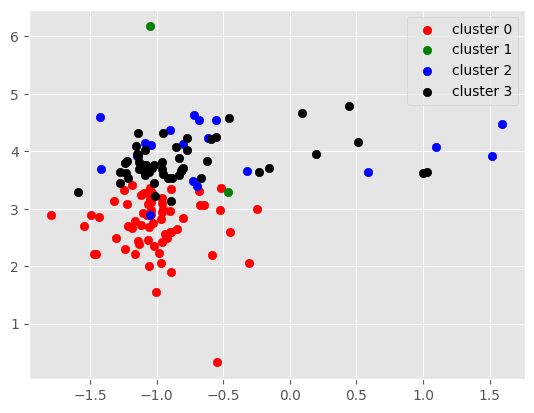

In [10]:
def plot_clusters(data):
    cluster_0 = data[data['cluster']==0]
    cluster_1 = data[data['cluster']==1]
    cluster_2 = data[data['cluster']==2]
    cluster_3 = data[data['cluster']==3]
    plt.scatter(cluster_0.iloc[:,5], cluster_0.iloc[:,3], color='red', label='cluster 0')
    plt.scatter(cluster_1.iloc[:,5], cluster_1.iloc[:,3], color='green', label='cluster 1')
    plt.scatter(cluster_2.iloc[:,5], cluster_2.iloc[:,3], color='blue', label='cluster 2')
    plt.scatter(cluster_3.iloc[:,5], cluster_3.iloc[:,3], color='black', label='cluster 3')
    plt.legend() # shows the key for the clusters (labels for each cluster)
    plt.show()
    return
plt.style.use('ggplot')
for i in data.index.get_level_values('date').unique().to_list(): # stores every unique date in a list
    g = data.xs(i, level=1) # for each i, g is returned a dataframe that contains rows only from that date
    # plt.title(f'Date {i}')
plot_clusters(g)
    
filtered_df = data[data['cluster']==3].copy()
filtered_df = filtered_df.reset_index(level='ticker')
filtered_df.index = filtered_df.index+pd.DateOffset(1)
filtered_df = filtered_df.reset_index().set_index(['date', 'ticker'])
dates = filtered_df.index.get_level_values(level='date').unique().to_list()
fixed_dates = {}
for d in dates:
    fixed_dates[d.strftime('%Y-%m-%d')] = filtered_df.xs(d, level='date').index.to_list()


In [11]:
stocks = data.index.get_level_values('ticker').unique().to_list()
new_df = yf.download(tickers=stocks, 
                      start=data.index.get_level_values('date').min()-pd.DateOffset(months=12),
                      end=data.index.get_level_values('date').max())
new_df

[*********************100%***********************]  305 of 305 completed


Price            Close                                                  \
Ticker            AMGN         AMT        AMZN        ANET         AON   
Date                                                                     
2010-06-30   35.578041   32.537422    5.463000         NaN   31.661232   
2010-07-01   35.185757   32.237640    5.548000         NaN   31.371239   
2010-07-02   34.969307   31.952482    5.457000         NaN   31.652702   
2010-07-06   34.698742   32.983433    5.503000         NaN   31.763586   
2010-07-07   34.766380   34.277634    5.671500         NaN   32.497105   
...                ...         ...         ...         ...         ...   
2025-12-23  329.208862  172.828308  232.139999  131.320007  355.869995   
2025-12-24  331.661865  173.115524  232.380005  130.770004  356.649994   
2025-12-26  330.638947  174.710007  232.520004  131.839996  356.649994   
2025-12-29  327.361664  175.830002  232.070007  134.149994  356.730011   
2025-12-30  326.428131  176.720001  232.529999  132.440002  356.489990   

Price                                                                  ...  \
Ticker            APA         APD         APH         APO         APP  ...   
Date                                                                   ...   
2010-06-30  61.637138   40.643909    4.312531         NaN         NaN  ...   
2010-07-01  61.278393   40.763062    4.339980         NaN         NaN  ...   
2010-07-02  60.656105   40.744240    4.277399         NaN         NaN  ...   
2010-07-06  60.685379   41.227139    4.268615         NaN         NaN  ...   
2010-07-07  63.731018   42.481373    4.422320         NaN         NaN  ...   
...               ...         ...         ...         ...         ...  ...   
2025-12-23  24.130535  242.996307  137.119995  147.766388  728.450012  ...   
2025-12-24  24.130535  244.058548  137.940002  148.244446  727.500000  ...   
2025-12-26  23.952230  245.627106  137.429993  147.915787  714.229980  ...   
2025-12-29  24.150347  246.053986  136.899994  146.670868  698.820007  ...   
2025-12-30  24.467333  247.016968  136.199997  145.465790  693.710022  ...   

Price         Volume                                                           \
Ticker           WMB       WMT     WTW       WY     WYNN       XOM        XYZ   
Date                                                                            
2010-06-30   9527110  55166400  180860  3824400  3424700  43944900        NaN   
2010-07-01  14321394  54343200  262136  3570000  3886500  47746400        NaN   
2010-07-02   8865554  40743900  354208  1859500  2525000  32767900        NaN   
2010-07-06  10147571  54676800  673309  2521000  2301300  36912100        NaN   
2010-07-07  13413027  48528600  482143  2567700  2754300  41797200        NaN   
...              ...       ...     ...      ...      ...       ...        ...   
2025-12-23   6099100  20319900  550200  5226800  1096700  12567600  5068200.0   
2025-12-24   2814500   9009600  235600  1935800   615000   6137400  3017700.0   
2025-12-26   2660600   9003800  289900  3510600   717300   8066100  3118400.0   
2025-12-29   4175000  12979600  351000  3841600  1017200  14782500  4216700.0   
2025-12-30   3535000  11730600  278000  3495800   689900  11150500  2958800.0   

Price                                    
Ticker          YUM      ZBH        ZTS  
Date                                     
2010-06-30  6687789  2761327        NaN  
2010-07-01  7388297  1997582        NaN  
2010-07-02  4930121  1682196        NaN  
2010-07-06  7066836  2225315        NaN  
2010-07-07  5881009  1886651        NaN  
...             ...      ...        ...  
2025-12-23  1660200  1337500  4952000.0  
2025-12-24   878600   623200  2369000.0  
2025-12-26  1086400   967500  3226800.0  
2025-12-29  1963000   924500  4465600.0  
2025-12-30  1158600   934500  3230200.0  

[3900 rows x 1525 columns]

Max Sharpe Ratio calculation failed for 2022-10-01, assigning equal-weights to all stocks
Max Sharpe Ratio calculation failed for 2022-09-01, assigning equal-weights to all stocks
Max Sharpe Ratio calculation failed for 2022-07-01, assigning equal-weights to all stocks
Max Sharpe Ratio calculation failed for 2016-04-01, assigning equal-weights to all stocks


<Axes: xlabel='Date'>

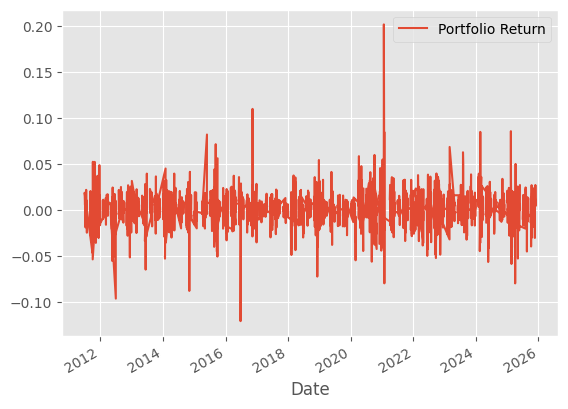

In [12]:
from pypfopt.efficient_frontier import EfficientFrontier
from pypfopt import risk_models, expected_returns
def optimize_weights(prices, lower_bound=0): # determine the weightage assigned to each stock
    returns = expected_returns.mean_historical_return(prices=prices, frequency=252) # returns the annualized expected returns of each stock
    cs = risk_models.CovarianceShrinkage(prices, frequency=252)
    cov = cs.ledoit_wolf() # returns the annualized sample covariance matrix of asset returns
    ef = EfficientFrontier(expected_returns=returns,
                           cov_matrix=cov,
                           weight_bounds=(lower_bound, 1),
                           solver='SCS')
    ef.max_sharpe()
    return ef.clean_weights() 

returns_dataframe = np.log(new_df['Close']).diff() # returns a MultiIndex Series of logged prices subtracted from the previous date

# Optimize portfolio for each month
portfolio_dfs = []
for start_date in fixed_dates.keys():
    end_date = (pd.to_datetime(start_date)+pd.offsets.MonthEnd(0)).strftime('%Y-%m-%d') # 0 in MonthEnd() means stay in the current month
    cols = fixed_dates[start_date]
    optimization_start_date = (pd.to_datetime(start_date)-pd.DateOffset(months=12)).strftime('%Y-%m-%d')
    optimization_end_date = (pd.to_datetime(start_date)-pd.DateOffset(days=1)).strftime('%Y-%m-%d') # strftime formats the date as a string
    optimization_df = new_df.loc[optimization_start_date:optimization_end_date,'Close'][cols]

    # Assign weights to each stock according to Max Sharpe Ratio. If failure occurs, assign equal weights to stocks
    success = False
    try:
        weights = optimize_weights(optimization_df, lower_bound=0.001)
        weights = pd.DataFrame(weights, index=[0])
        success = True
    except ValueError:
        print(f"Max Sharpe Ratio calculation failed for {start_date}, assigning equal-weights to all stocks")
    if success == False:
        weights = pd.DataFrame(
            [1/len(optimization_df.columns) for i in range(len(optimization_df.columns))], 
            index=optimization_df.columns.to_list(),
            columns=pd.Series(0)).T
        
    temp_df = returns_dataframe[start_date:end_date] # obtain returns for the current month
    # reset the date level for the "returns" and "weights" Series, then merge the two
    temp_df = temp_df.stack().to_frame('Return').reset_index(level=0).merge(
        weights.stack().to_frame('Weight').reset_index(level=0, drop=True), # drop=True discards the index level that's been converted into a column
        left_index=True, right_index=True # only include rows where the index values match in both dataframes
    ).reset_index().set_index(['Date', 'Ticker'])
    temp_df['Weighted Return'] = temp_df['Return'] * temp_df['Weight']
    
    # returns a Series of sum of portfolio return for each month
    temp_df = temp_df.groupby(level=0)['Weighted Return'].sum().to_frame('Portfolio Return') 
    portfolio_dfs.append(temp_df) # append dataframe to list
portfolio_df = pd.concat(portfolio_dfs).drop_duplicates()
portfolio_df.plot()


In [13]:
end_date = dt.datetime.today()
start_date = pd.to_datetime(end_date) - pd.DateOffset(365*15)
spy = yf.download(tickers='SPY', start=start_date, end=end_date)
spy_return = np.log(spy['Close']).diff().dropna().rename({'SPY':'SPY Buy&Hold'}, axis=1)
spy_return.columns.name = None
portfolio_df = portfolio_df.merge(spy_return, left_index=True, right_index=True).sort_index()
portfolio_df

[*********************100%***********************]  1 of 1 completed


,Portfolio Return,SPY Buy&Hold
Date,,
2011-07-01,0.018710,0.014668
2011-07-05,0.005489,-0.000821
2011-07-06,0.010702,0.001195
2011-07-07,0.004703,0.010323
2011-07-08,-0.006671,-0.007118
...,...,...
2025-11-21,0.013621,0.009912
2025-11-24,0.008548,0.014611
2025-11-25,0.004936,0.009362


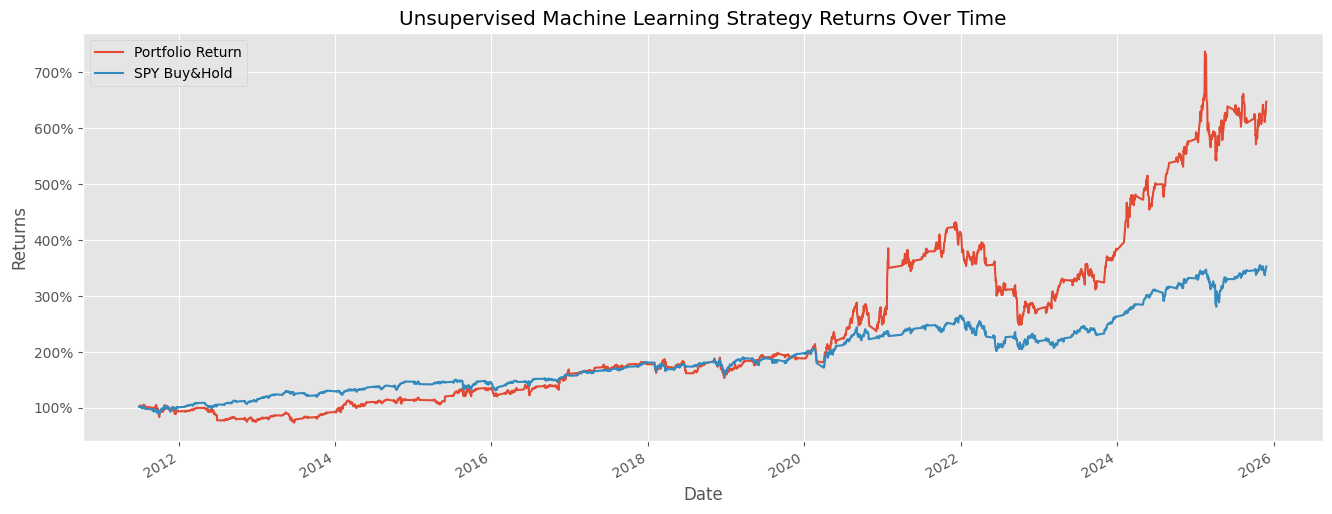

In [14]:
import matplotlib.ticker as mtick

plt.style.use('ggplot')
portfolio_cumulative_returns = np.exp(np.log1p(portfolio_df).cumsum()) # log1p means log(1+x) but handles floating-piont precision better
# .cumsum() calculates the total return relative to the start and .exp converts it to a growth factor
# Totalling logged returns will give the logged growth factor (e.g., ln(1.3))
# To obtain the growth factor, .exp will cancel out the ln
portfolio_cumulative_returns[:end_date].plot(figsize=(16,6))
plt.title('Unsupervised Machine Learning Strategy Returns Over Time')
plt.ylabel('Returns')
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.savefig('../../results/unsupervised_ml_returns.png', dpi=150, bbox_inches='tight')
plt.show()